# Multilabel Logistic Regression

This notebook evaluates whether multilabtel logistic regression can predict five diagnostic superclasses (NORM, MI, STTC, CD, and HYP) using the PTB-XL dataset. It uses five independent binary logistic regression classifiers, allowing each ECG to have multiple diagnostic labels, and compares models using 60 ECG-derived statistical features, principal component analysis (PCA), and additional demographic information (age and sex).

My goal of this notebook is to be able to answer these guiding questions: 

1. How well do 60 ECG-derived statistical features predict the five diagnostic superclasses?

2. Does PCA preserve performance when reducing the 60 features to 40 components?

3. Which ECG-derived summary features are most associated with MI prediction?

4. Does adding age and sex improve prediction over ECG-only features? 

## 1. Loading and verifying the processed data 

I will start with the preprocessed PTB-XL recordings. Each of the 10-second ECGs contains 1000 time points (samples) from 12 leads. The waveform array, diagnostic labels, demographic table, and official split assignments (training, validation, testing) must have matching ECG IDs and row order. I'm completing these checks now so that I do not accidentally pair a waveform with the wrong diagnosis. 

*(Side note: I will open the waveforms with `mmap_mode='r'` so that the full dataset does not need to be loaded into RAM)*

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    f1_score, recall_score, confusion_matrix, roc_curve
)

# would need to change this path to your local path
DATA_DIR = Path("/work/users/s/b/sbalaji/BIOS784_Project/data/processed")
X = np.load(DATA_DIR / "waveforms.npy", mmap_mode="r")
recording_ids = np.load(DATA_DIR / "recording_ids.npy")
labels = pd.read_csv(DATA_DIR / "labels.csv")
predictors = pd.read_csv(DATA_DIR / "predictors.csv")
splits = pd.read_csv(DATA_DIR / "splits.csv")

CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
assert np.array_equal(labels.ecg_id.to_numpy(), recording_ids)
assert np.array_equal(predictors.ecg_id.to_numpy(), recording_ids)
assert np.array_equal(splits.ecg_id.to_numpy(), recording_ids)

df = (labels.merge(predictors[["ecg_id", "age", "sex"]], on="ecg_id", validate="one_to_one")
            .merge(splits[["ecg_id", "partition"]], on="ecg_id", validate="one_to_one"))
assert np.array_equal(df.ecg_id.to_numpy(), recording_ids)

print("ECG waveforms:", X.shape)
print("Diagnostic labels:", CLASSES)
print("Official partitions:", df.partition.value_counts().to_dict())

ECG waveforms: (21799, 1000, 12)
Diagnostic labels: ['NORM', 'MI', 'STTC', 'CD', 'HYP']
Official partitions: {'train': 17418, 'test': 2198, 'validation': 2183}


## 2. Defining the five multilabel outcomes 

Each of the recordings can have more than one diagnostic superclass: NORM (normal), MI (myocardial infarction), STTC (ST/T changes), CD (conduction disturbance), and HYP (hypertrophy). Therefore, I'm training five independent binary classifiers, instead of having a model that forces a patient to have exactly one diagnosis. 

I'm excluding ECGs without a diagnostic superclass label and I'm retaining and official patient-disjoint partitions: 17418 training, 2183 validation, and 2198 test recordings, and the outcome matrix has five columns (one for each label). 

In [2]:
# Showing the five diagnostic superclasses
CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]

# Verify that all files have matching ECG IDs
assert np.array_equal(labels["ecg_id"].to_numpy(), recording_ids)
assert np.array_equal(predictors["ecg_id"].to_numpy(), recording_ids)
assert np.array_equal(splits["ecg_id"].to_numpy(), recording_ids)

# Combining labels, age, sex, and split assignments
df = (
    labels
    .merge(
        predictors[["ecg_id", "age", "sex"]],
        on="ecg_id",
        validate="one_to_one"
    )
    .merge(
        splits[["ecg_id", "partition"]],
        on="ecg_id",
        validate="one_to_one"
    )
)

# Verifying that merging preserved waveform order
assert np.array_equal(df["ecg_id"].to_numpy(), recording_ids)

# Excluding ECGs without any diagnostic superclass label
eligible = df["has_diagnostic_label"].eq(1)

# Identifying training, validation, and test recordings
train_idx = np.flatnonzero(
    (eligible & df["partition"].eq("train")).to_numpy()
)
val_idx = np.flatnonzero(
    (eligible & df["partition"].eq("validation")).to_numpy()
)
test_idx = np.flatnonzero(
    (eligible & df["partition"].eq("test")).to_numpy()
)

# Creating the five binary outcomes
y = df[CLASSES].to_numpy(dtype=np.int8)

y_train = y[train_idx]
y_val = y[val_idx]
y_test = y[test_idx]

print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

print("\nTraining label matrix:", y_train.shape)
print("\nTraining class prevalence:")
display(pd.Series(y_train.mean(axis=0), index=CLASSES))

# The index of MI in the multilabel outcome matrix
mi_idx = CLASSES.index("MI")


Training: 17084
Validation: 2146
Test: 2158

Training label matrix: (17084, 5)

Training class prevalence:


NORM    0.444627
MI      0.256322
STTC    0.245025
CD      0.228694
HYP     0.124034
dtype: float64

### Checking patient-disjointness across partitions

Another note is that multiple ECGs can belong to the same patient. If a patient's ECG appeared both in training and testing, then the performance of the model could be inflated with patient specific similarities. Therefore, I'm checking that the official partitions have zero overlapping patient IDs. 

In [3]:
patient_ids = predictors["patient_id"].to_numpy()
groups = {
    part: set(patient_ids[df.partition.eq(part).to_numpy()])
    for part in ["train", "validation", "test"]
}
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    overlap = len(groups[a] & groups[b])
    print(f"{a} / {b} patient overlap: {overlap}")
    assert overlap == 0

train / validation patient overlap: 0
train / test patient overlap: 0
validation / test patient overlap: 0


## 3. Extracting ECG summary features and fitting the baseline model 

Instead of using all 12000 waveform values directly, I'm summarising each lead with the mean, standard deviation, minimum, maximum, and root square mean (RMS). This creates 60 features that describe the signal's overall amplitude and variability. 

Each of the derived features is standardised using the training-set mean and standard deviation. Logistic regression uses these scaled features to estimate the probability of MI, and validation AUROC and AUPRC says how well it distinguishes the two groups without using the held-out test set. 

In [4]:
def extract_ecg_features(waveforms):
    """Extracting 5 statistical features from each of 12 ECG leads."""
    features = []

    for batch_start in range(0, len(waveforms), 1000):
        batch = np.asarray(
            waveforms[batch_start:batch_start + 1000],
            dtype=np.float32
        )

        mean = batch.mean(axis=1)
        std = batch.std(axis=1)
        minimum = batch.min(axis=1)
        maximum = batch.max(axis=1)
        rms = np.sqrt(np.mean(batch**2, axis=1))

        batch_features = np.concatenate(
            [mean, std, minimum, maximum, rms],
            axis=1
        )

        features.append(batch_features)

    return np.vstack(features)

In [6]:
X_train_features = extract_ecg_features(X[train_idx])
X_val_features = extract_ecg_features(X[val_idx])
X_test_features = extract_ecg_features(X[test_idx])

feature_scaler = StandardScaler()
X_train_features_scaled = feature_scaler.fit_transform(X_train_features)
X_val_features_scaled = feature_scaler.transform(X_val_features)
X_test_features_scaled = feature_scaler.transform(X_test_features)

print("Feature matrices:", X_train_features_scaled.shape,
      X_val_features_scaled.shape, X_test_features_scaled.shape)
assert np.isfinite(X_train_features_scaled).all()
assert np.isfinite(X_val_features_scaled).all()
assert np.isfinite(X_test_features_scaled).all()

Feature matrices: (17084, 60) (2146, 60) (2158, 60)


This tells me that the model receives 17,084 × 60 training features, 2,146 × 60 validation features, and 2,158 × 60 test features.

## 4. Fitting five ECG-only logistic regression classifiers 

For each superclass, I'm fitting a separate logistic regression to the 60 standardized features. Each model outputs a probability for its own label, so an ECG may receive high probabilities for several abnormalities simultaneously.

I will report AUROC to assess how well positive and negative recordings are ranked, and AUPRC to reflect precision–recall performance when some diagnoses are less common.

In [7]:
from sklearn.metrics import roc_auc_score, average_precision_score

models_60 = {}
results_60 = []

for i, cls in enumerate(CLASSES):

    model = LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train_features_scaled, y_train[:, i])

    train_probs = model.predict_proba(X_train_features_scaled)[:, 1]
    val_probs = model.predict_proba(X_val_features_scaled)[:, 1]

    models_60[cls] = model

    results_60.append({
        "Class": cls,
        "Train AUROC": roc_auc_score(y_train[:, i], train_probs),
        "Validation AUROC": roc_auc_score(y_val[:, i], val_probs),
        "Validation AUPRC": average_precision_score(y_val[:, i], val_probs),
        "Iterations": model.n_iter_[0]
    })

results_60_df = pd.DataFrame(results_60)

display(results_60_df.round(4))

print("\nMacro Validation AUROC:",
      round(results_60_df["Validation AUROC"].mean(), 4))

print("Macro Validation AUPRC:",
      round(results_60_df["Validation AUPRC"].mean(), 4))

,Class,Train AUROC,Validation AUROC,Validation AUPRC,Iterations
0,NORM,0.7826,0.7763,0.6901,131
1,MI,0.7632,0.7589,0.4945,150
2,STTC,0.6975,0.7065,0.4420,146
3,CD,0.8289,0.8130,0.6422,93
4,HYP,0.8385,0.8367,0.5133,101



Macro Validation AUROC: 0.7783
Macro Validation AUPRC: 0.5564


Here, the multilabel logistic regression model achieved moderate predictive performance, with a macro validation AUROC of 0.7783 and AUPRC of 0.5564. Performance was strongest for HYP (0.8367) and CD (0.8130), while STTC (0.7065) was the most difficult to distinguish. The small differences between training and validation AUROC suggest limited overfitting. Overall, these results support multilabel logistic regression as a reasonable baseline for predicting multiple, potentially co-occurring ECG abnormalities.

# 5. Comparing original features with PCA (40 components) 

PCA constructs new mutually orthogonal features that explain variation in the standardized ECG summaries. I'm retaining 40 principal components from the original 60 features and fitting five new logistic regression classifiers, one for each diagnostic category. Since PCA and logistic regression are both fitted only on the training data, the validation recordings are transformed without refitting.

Using PCA allows us to investigate whether a more compact representation of the ECG data preserves information useful for predicting multiple cardiac abnormalities. It is important to recognize that high explained variance does not necessarily guarantee strong predictive performance, since the directions capturing the most overall variation may not be the most useful for distinguishing diagnoses. I'll compare the validation AUROC and AUPRC for each diagnostic class, along with their macro averages, to evaluate whether dimensionality reduction affects predictive performance.

In [8]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# Fitting PCA on training data only
pca_40 = PCA(n_components=40, random_state=42)

X_train_pca40 = pca_40.fit_transform(X_train_features_scaled)
X_val_pca40 = pca_40.transform(X_val_features_scaled)

models_pca40 = {}
results_pca40 = []

for i, cls in enumerate(CLASSES):

    model = LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train_pca40, y_train[:, i])

    val_probs = model.predict_proba(X_val_pca40)[:, 1]

    models_pca40[cls] = model

    results_pca40.append({
        "Class": cls,
        "Validation AUROC": roc_auc_score(y_val[:, i], val_probs),
        "Validation AUPRC": average_precision_score(y_val[:, i], val_probs)
    })

results_pca40_df = pd.DataFrame(results_pca40)

# Comparing the two approaches
comparison_df = results_60_df[
    ["Class", "Validation AUROC", "Validation AUPRC"]
].merge(
    results_pca40_df,
    on="Class",
    suffixes=("_60", "_PCA40")
)

display(comparison_df.round(4))

print("\n60-feature macro AUROC:",
      round(comparison_df["Validation AUROC_60"].mean(), 4))

print("PCA-40 macro AUROC:",
      round(comparison_df["Validation AUROC_PCA40"].mean(), 4))

print("\n60-feature macro AUPRC:",
      round(comparison_df["Validation AUPRC_60"].mean(), 4))

print("PCA-40 macro AUPRC:",
      round(comparison_df["Validation AUPRC_PCA40"].mean(), 4))

,Class,Validation AUROC_60,Validation AUPRC_60,Validation AUROC_PCA40,Validation AUPRC_PCA40
0,NORM,0.7763,0.6901,0.7767,0.6931
1,MI,0.7589,0.4945,0.7556,0.4883
2,STTC,0.7065,0.4420,0.7043,0.4368
3,CD,0.8130,0.6422,0.8134,0.6350
4,HYP,0.8367,0.5133,0.8335,0.5013



60-feature macro AUROC: 0.7783
PCA-40 macro AUROC: 0.7767

60-feature macro AUPRC: 0.5564
PCA-40 macro AUPRC: 0.5509


Here, PCA changes the feature representation without adding new information. On the validation set. Macro AUROC decreased by only 0.0016 and macro AUPRC by 0.0055, suggesting that reducing the original 60 features to 40 principal components preserved nearly all of the predictive performance. This indicates that the 20 discarded dimensions contributed relatively little to the models' ability to distinguish between diagnostic categories.

# Visualise validation AUROC and AUPRC 

Now, I will make plots to compare the original and PCA-based classifiers separately for each diagnostic superclass, where similar bars indicate that PCA preserves most discriminative information.

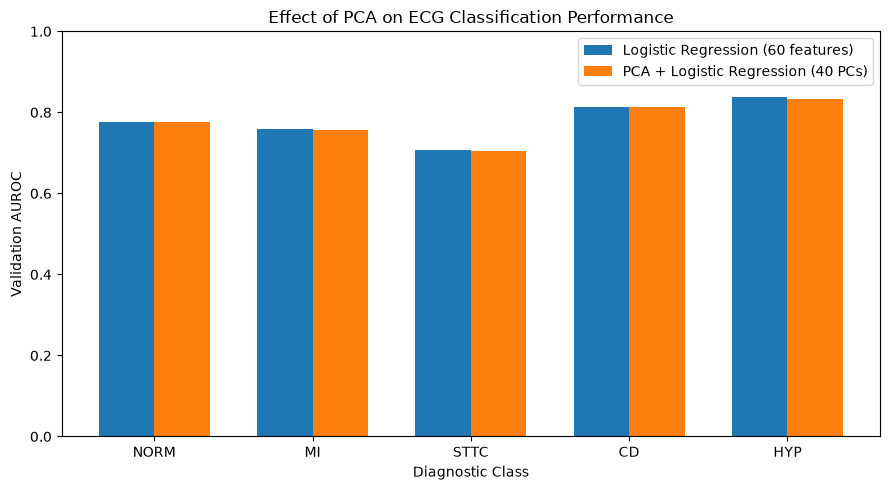

In [9]:
import matplotlib.pyplot as plt
import numpy as np

classes = comparison_df["Class"].tolist()
x = np.arange(len(classes))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    comparison_df["Validation AUROC_60"],
    width,
    label="Logistic Regression (60 features)"
)

ax.bar(
    x + width / 2,
    comparison_df["Validation AUROC_PCA40"],
    width,
    label="PCA + Logistic Regression (40 PCs)"
)

ax.set_xlabel("Diagnostic Class")
ax.set_ylabel("Validation AUROC")
ax.set_title("Effect of PCA on ECG Classification Performance")
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.set_ylim(0, 1)
ax.legend()

plt.tight_layout()
plt.show()

# 6. Identifying ECG features associated with MI prediction 

Now, I'm going to investigate which ECG summary features contribute most to predicting MI-related abnormalities. I'll start by examining the logistic regression coefficients, where larger absolute values indicate stronger associations with the predicted MI log-odds, and the signs indicate whether those associations are positive or negative.

Since ECG features can be correlated, coefficient magnitudes alone may not fully capture their importance. To complement this analysis, I'll use permutation importance on the validation set to measure how much the model's AUROC decreases when each feature is randomly shuffled.

In [10]:
# These are the names of the 12 ECG leads
leads = [
    "I", "II", "III", "aVR", "aVL", "aVF",
    "V1", "V2", "V3", "V4", "V5", "V6"
]

statistics = ["Mean", "Std", "Min", "Max", "RMS"]

# Matching the ordering used in feature extraction
feature_names = [
    f"{stat}_{lead}"
    for stat in statistics
    for lead in leads
]

# Getting MI logistic regression coefficients
mi_coefficients = models_60["MI"].coef_[0]

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": mi_coefficients,
    "Absolute Coefficient": np.abs(mi_coefficients)
})

# Sorting by absolute coefficient magnitude
feature_importance_df = feature_importance_df.sort_values(
    "Absolute Coefficient",
    ascending=False
)

print("Top 15 Features Associated with MI Prediction:")
display(feature_importance_df.head(15).round(4))

Top 15 Features Associated with MI Prediction:


,Feature,Coefficient,Absolute Coefficient
16,Std_aVL,1.2768,1.2768
12,Std_I,-1.2197,1.2197
40,Max_aVL,1.1331,1.1331
53,RMS_aVF,-1.1201,1.1201
41,Max_aVF,0.9177,0.9177
14,Std_III,0.9130,0.9130
59,RMS_V6,-0.8218,0.8218
50,RMS_III,-0.7319,0.7319
27,Min_aVR,0.7240,0.7240
55,RMS_V2,-0.7164,0.7164


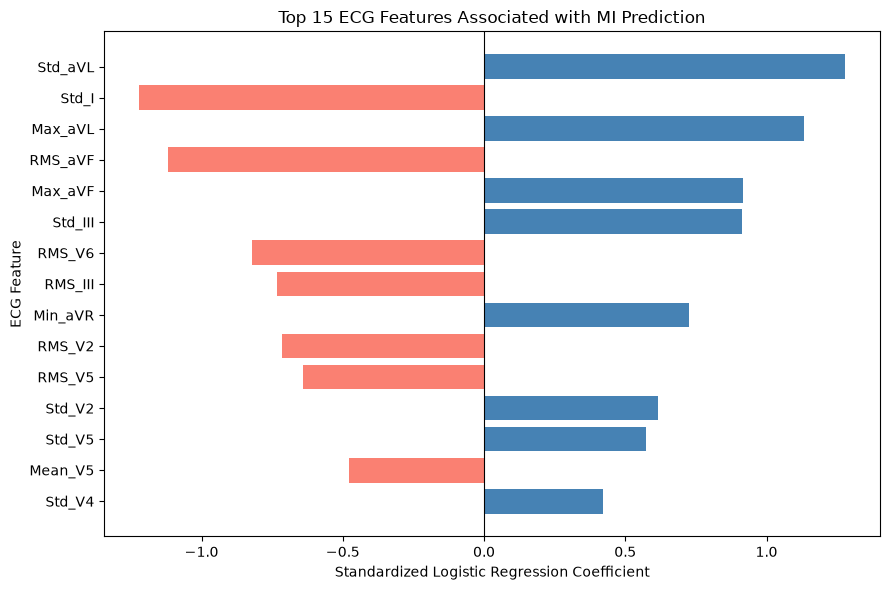

In [11]:
import matplotlib.pyplot as plt
import numpy as np

top_features = feature_importance_df.head(15).iloc[::-1]

colors = np.where(
    top_features["Coefficient"] > 0,
    "steelblue",
    "salmon"
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    top_features["Feature"],
    top_features["Coefficient"],
    color=colors
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_xlabel("Standardized Logistic Regression Coefficient")
ax.set_ylabel("ECG Feature")
ax.set_title("Top 15 ECG Features Associated with MI Prediction")

plt.tight_layout()
plt.show()

Here, the magnitude of each coefficient indicates the strength of its association with the predicted MI log-odds, while its sign indicates whether the association is positive or negative. However, these coefficients should be interpreted cautiously, since correlated ECG features can influence one another, and larger coefficients do not necessarily imply greater clinical significance.

# Checking  MI permutation importance 

Now, I'm going to use permutation importance to further investigate which ECG summary features contribute most to MI prediction. I'll measure how much the model's validation AUROC decreases when each feature is randomly shuffled, while keeping the fitted model unchanged.

A larger decrease in AUROC suggests that the model relies more heavily on that feature for prediction. However, since ECG features can be highly correlated, a small decrease does not necessarily mean that a feature is unimportant, as other features may contain similar information.

In [12]:
from sklearn.inspection import permutation_importance

# MI labels for validation data
y_val_mi = y_val[:, mi_idx]

# Calculating permutation importance
perm_result = permutation_importance(
    models_60["MI"],
    X_val_features_scaled,
    y_val_mi,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

# Organising results
permutation_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance Mean": perm_result.importances_mean,
    "Importance SD": perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    "Importance Mean",
    ascending=False
)

print("Top 15 Features by Permutation Importance:")
display(permutation_df.head(15).round(4))

Top 15 Features by Permutation Importance:


,Feature,Importance Mean,Importance SD
16,Std_aVL,0.1745,0.0093
40,Max_aVL,0.1714,0.0070
14,Std_III,0.1187,0.0070
27,Min_aVR,0.1179,0.0113
12,Std_I,0.0995,0.0095
53,RMS_aVF,0.0828,0.0040
19,Std_V2,0.0584,0.0057
58,RMS_V5,0.0492,0.0041
41,Max_aVF,0.0474,0.0046
22,Std_V5,0.0429,0.0028


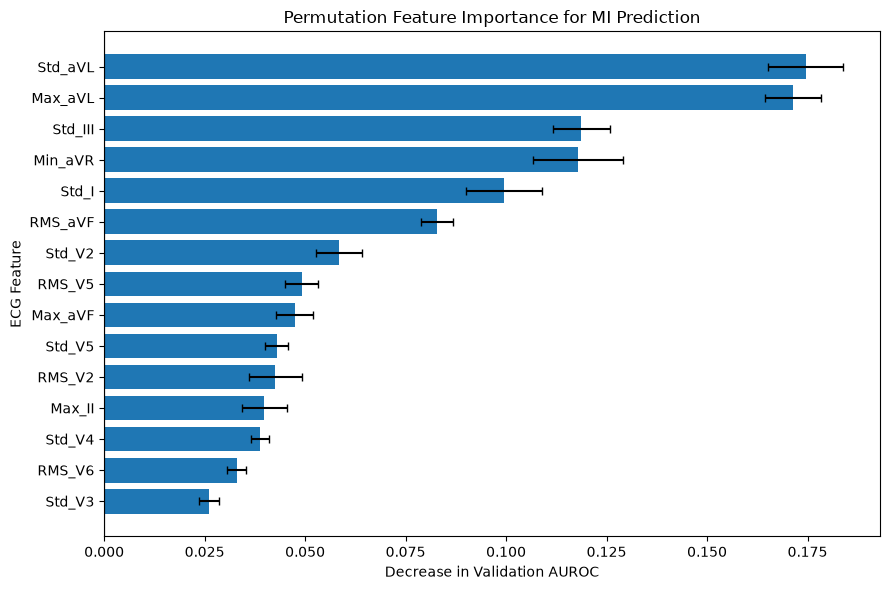

In [13]:
import matplotlib.pyplot as plt

top_perm = permutation_df.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    top_perm["Feature"],
    top_perm["Importance Mean"],
    xerr=top_perm["Importance SD"],
    capsize=3
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_xlabel("Decrease in Validation AUROC")
ax.set_ylabel("ECG Feature")
ax.set_title("Permutation Feature Importance for MI Prediction")

plt.tight_layout()
plt.show()

These permutation importance results suggest that Std_aVL and Max_aVL contribute most strongly to MI prediction, followed by Std_III and Min_aVR. Shuffling these features produces the largest decreases in validation AUROC, indicating that the model relies heavily on them to distinguish MI-related ECGs from normal recordings.

These results are broadly consistent with the logistic regression coefficient analysis, although the feature rankings differ slightly. This is because coefficients measure associations within the fitted model, while permutation importance measures how much each feature contributes to predictive performance. Neither measure necessarily indicates clinical significance.

# 7. Preparing age and sex for the demographic comparison 

Now, I'm going to investigate whether including patient characteristics improves MI prediction beyond the original ECG summary features. I'll add age and sex to the 60 ECG features and compare the model's predictive performance with and without these additional variables.

Although there are no missing values in the original age and sex columns, 293 recordings have age recorded as 300, which likely represents a de-identification placeholder. I'll treat these values as missing and replace them with the training-set median age of 61 years. Age will then be standardized using training-set statistics, while sex will retain its original binary encoding (0/1). Height and weight will be excluded.

This gives us 62 predictors, with all preprocessing transformations fitted only on the training data. 

In [14]:
# Extracting age and sex for the original five-superclass dataset
# df is already aligned with the waveform array X

demographic_cols = ["age", "sex"]

demo_train = df.iloc[train_idx][demographic_cols].copy()
demo_val = df.iloc[val_idx][demographic_cols].copy()
demo_test = df.iloc[test_idx][demographic_cols].copy()

# Inspecting missing values and distributions
print("Missing values:")
print(
    pd.DataFrame({
        "Training": demo_train.isna().sum(),
        "Validation": demo_val.isna().sum(),
        "Test": demo_test.isna().sum()
    })
)

print("\nSex values:")
print(df["sex"].value_counts(dropna=False))

print("\nAge summary:")
print(df["age"].describe())

Missing values:
     Training  Validation  Test
age         0           0     0
sex         0           0     0

Sex values:
sex
0    11354
1    10445
Name: count, dtype: int64

Age summary:
count    21799.000000
mean        62.769301
std         32.308813
min          2.000000
25%         50.000000
50%         62.000000
75%         72.000000
max        300.000000
Name: age, dtype: float64


In [15]:
# Checking unusually large age values
print("Recordings with age > 100:")
print((df["age"] > 100).sum())

print("\nAge values above 100:")
print(
    df.loc[df["age"] > 100, "age"]
      .value_counts()
      .sort_index()
)

print("\nAge > 100 by partition:")
print(
    pd.crosstab(
        df["partition"],
        df["age"] > 100
    )
)

print("\nAge > 100 by diagnostic superclass:")
print(
    df.loc[df["age"] > 100, CLASSES].sum()
)

Recordings with age > 100:
293

Age values above 100:
age
300.0    293
Name: count, dtype: int64

Age > 100 by partition:
age         False  True 
partition               
test         2164     34
train       17201    217
validation   2141     42

Age > 100 by diagnostic superclass:
NORM     31
MI      121
STTC    136
CD      142
HYP      56
dtype: int64


In [16]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import numpy as np

# Making copies of demographic data
demo_train_clean = demo_train.copy()
demo_val_clean = demo_val.copy()
demo_test_clean = demo_test.copy()

# Treating age 300 as a de-identification code
for demo in [demo_train_clean, demo_val_clean, demo_test_clean]:
    demo.loc[demo["age"] == 300, "age"] = np.nan

# Imputing missing ages using training-set median
age_imputer = SimpleImputer(strategy="median")

age_train = age_imputer.fit_transform(
    demo_train_clean[["age"]]
)
age_val = age_imputer.transform(
    demo_val_clean[["age"]]
)
age_test = age_imputer.transform(
    demo_test_clean[["age"]]
)

# Standardising age using training statistics
age_scaler = StandardScaler()

age_train_scaled = age_scaler.fit_transform(age_train)
age_val_scaled = age_scaler.transform(age_val)
age_test_scaled = age_scaler.transform(age_test)

# Sex is already binary (0/1)
sex_train = demo_train_clean[["sex"]].to_numpy()
sex_val = demo_val_clean[["sex"]].to_numpy()
sex_test = demo_test_clean[["sex"]].to_numpy()

# Combining standardized ECG features with demographics
X_train_ecg_demo = np.column_stack([
    X_train_features_scaled,
    age_train_scaled,
    sex_train
])

X_val_ecg_demo = np.column_stack([
    X_val_features_scaled,
    age_val_scaled,
    sex_val
])

X_test_ecg_demo = np.column_stack([
    X_test_features_scaled,
    age_test_scaled,
    sex_test
])

print("Training shape:", X_train_ecg_demo.shape)
print("Validation shape:", X_val_ecg_demo.shape)
print("Test shape:", X_test_ecg_demo.shape)

print("\nTraining median age:", age_imputer.statistics_[0])

print("\nAny missing values?")
print("Training:", np.isnan(X_train_ecg_demo).any())
print("Validation:", np.isnan(X_val_ecg_demo).any())
print("Test:", np.isnan(X_test_ecg_demo).any())

Training shape: (17084, 62)
Validation shape: (2146, 62)
Test shape: (2158, 62)

Training median age: 61.0

Any missing values?
Training: False
Validation: False
Test: False


The demographic checks identified 293 recordings with age recorded as 300, which were treated as missing values and replaced using the training-set median age of 61 years. After imputation and standardization, the resulting dataset contains 62 predictors with no missing values.

All preprocessing transformations were fitted using only the training data, ensuring that no information from the validation or test sets was used during preprocessing.

# 8. Fitting ECG + age/sex classifiers and comparing validation performance 

Now, I'm going to compare the performance of the logistic regression models using 62 predictors (ECG features, age, and sex) against the original 60-feature models on the same validation set. By keeping the models, data splits, and ECG features consistent, I can assess whether adding age and sex improves predictive performance.

The results show that including demographic information increased macro validation AUROC from 0.7783 to 0.8022 and macro AUPRC from 0.5563 to 0.5912. The largest improvements were observed for NORM and STTC, while CD showed very little change. This suggests that age and sex provide additional predictive information for certain ECG diagnoses, although these associations do not necessarily imply causation.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd

# Training five binary classifiers with ECG + demographics
models_ecg_demo = {}
demo_val_results = []

for i, cls in enumerate(CLASSES):

    model = LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=1000,
        random_state=42
    )

    model.fit(
        X_train_ecg_demo,
        y_train[:, i]
    )

    models_ecg_demo[cls] = model

    # Validation predictions
    val_probs = model.predict_proba(
        X_val_ecg_demo
    )[:, 1]

    # Comparing against existing ECG-only model
    ecg_only_probs = models_60[cls].predict_proba(
        X_val_features_scaled
    )[:, 1]

    demo_val_results.append({
        "Class": cls,
        "AUROC_ECG": roc_auc_score(
            y_val[:, i], ecg_only_probs
        ),
        "AUROC_ECG_Demo": roc_auc_score(
            y_val[:, i], val_probs
        ),
        "AUPRC_ECG": average_precision_score(
            y_val[:, i], ecg_only_probs
        ),
        "AUPRC_ECG_Demo": average_precision_score(
            y_val[:, i], val_probs
        )
    })

demo_val_results_df = pd.DataFrame(demo_val_results)

display(demo_val_results_df.round(4))

print("\nMacro-average validation metrics:")
print(
    demo_val_results_df[
        ["AUROC_ECG", "AUROC_ECG_Demo",
         "AUPRC_ECG", "AUPRC_ECG_Demo"]
    ].mean().round(4)
)

,Class,AUROC_ECG,AUROC_ECG_Demo,AUPRC_ECG,AUPRC_ECG_Demo
0,NORM,0.7763,0.8188,0.6901,0.7590
1,MI,0.7589,0.7832,0.4945,0.5336
2,STTC,0.7065,0.7470,0.4420,0.4971
3,CD,0.8130,0.8137,0.6422,0.6427
4,HYP,0.8367,0.8483,0.5133,0.5235



Macro-average validation metrics:
AUROC_ECG         0.7783
AUROC_ECG_Demo    0.8022
AUPRC_ECG         0.5564
AUPRC_ECG_Demo    0.5912
dtype: float64


The validation results show that adding age and sex improved overall predictive performance, with macro AUROC increasing by 0.0239 (from 0.7783 to 0.8022) and macro AUPRC increasing by 0.0348 (from 0.5564 to 0.5912).

However, the improvement was not consistent across all diagnostic categories. In particular, CD showed very little change, suggesting that the additional predictive value of demographic information depends on the specific ECG diagnosis.

# 9. Evaluating all models on the held-out test set 

Now, I'm going to evaluate the final ECG-only, PCA-40, and ECG + demographics logistic regression models on the held-out test set to compare how well each approach generalizes to previously unseen ECG recordings.

I'll compare their macro-averaged AUROC, AUPRC, and F1 scores across the five diagnostic categories. Macro averaging gives each class equal weight, regardless of how frequently it appears in the dataset. AUROC measures how well the models distinguish between diagnoses across different thresholds, AUPRC summarizes precision–recall performance, and F1 evaluates the balance between precision and recall at a chosen threshold.

For all logistic regression models, I'll use a fixed classification threshold of 0.5 for each label. Since the CNN model uses class-specific thresholds selected using validation data, its F1 scores cannot be directly compared with those of logistic regression without using the same threshold-selection approach.

In [18]:
X_test_pca40 = pca_40.transform(X_test_features_scaled)

test_results = []
for i, cls in enumerate(CLASSES):
    p_ecg = models_60[cls].predict_proba(X_test_features_scaled)[:, 1]
    p_pca = models_pca40[cls].predict_proba(X_test_pca40)[:, 1]
    test_results.append({
        "Class": cls,
        "AUROC_60": roc_auc_score(y_test[:, i], p_ecg),
        "AUPRC_60": average_precision_score(y_test[:, i], p_ecg),
        "AUROC_PCA40": roc_auc_score(y_test[:, i], p_pca),
        "AUPRC_PCA40": average_precision_score(y_test[:, i], p_pca),
    })
test_results_df = pd.DataFrame(test_results)
display(test_results_df.round(4))

,Class,AUROC_60,AUPRC_60,AUROC_PCA40,AUPRC_PCA40
0,NORM,0.7556,0.6734,0.7553,0.6717
1,MI,0.7519,0.5091,0.7515,0.5064
2,STTC,0.6925,0.4493,0.6910,0.4481
3,CD,0.7948,0.6206,0.7952,0.6170
4,HYP,0.8140,0.5054,0.8126,0.5047


In [19]:
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score
import numpy as np
import pandas as pd

# Generating test predictions from existing five-class models
probs_60 = np.column_stack([
    models_60[cls].predict_proba(X_test_features_scaled)[:, 1]
    for cls in CLASSES
])

probs_pca40 = np.column_stack([
    models_pca40[cls].predict_proba(X_test_pca40)[:, 1]
    for cls in CLASSES
])

# Converting probabilities to binary predictions
preds_60 = (probs_60 >= 0.5).astype(int)
preds_pca40 = (probs_pca40 >= 0.5).astype(int)

# Evaluating each model
multilabel_results = []

for name, probabilities, predictions in [
    ("Logistic Regression (60 features)", probs_60, preds_60),
    ("Logistic Regression + PCA (40 PCs)", probs_pca40, preds_pca40)
]:
    multilabel_results.append({
        "Model": name,
        "Macro AUROC": roc_auc_score(
            y_test, probabilities, average="macro"
        ),
        "Macro AUPRC": average_precision_score(
            y_test, probabilities, average="macro"
        ),
        "Macro F1": f1_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        )
    })

multilabel_results_df = pd.DataFrame(multilabel_results)

display(multilabel_results_df.round(4))

,Model,Macro AUROC,Macro AUPRC,Macro F1
0,Logistic Regression (60 features),0.7617,0.5516,0.4144
1,Logistic Regression + PCA (40 PCs),0.7611,0.5496,0.4092


The held-out test results show that PCA preserved nearly all of the predictive performance of the original logistic regression model. Macro AUROC decreased only slightly from 0.7617 to 0.7611, while macro AUPRC decreased from 0.5516 to 0.5496.

Macro F1 also decreased slightly from 0.4144 to 0.4092, suggesting that dimensionality reduction had a somewhat greater effect on classification decisions at the fixed 0.5 threshold. Overall, these results suggest that reducing the original 60 ECG features to 40 principal components retains most of the information useful for predicting the five diagnostic categories.

# Comparing ECG only and ECG + demographics on test recordings 

Now, I'm going to compare the held-out test performance of the ECG-only and ECG + demographics models to determine whether the improvements observed during validation generalize to previously unseen patients.

Since both models use the same 60 ECG summary features, any consistent improvement from adding age and sex would suggest that these variables provide additional predictive information beyond what is captured by the ECG features alone. However, these results would not necessarily guarantee similar improvements in other clinical populations.

In [20]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score
)

# Testing probabilities from the ECG + demographics models
probs_ecg_demo = np.column_stack([
    models_ecg_demo[cls].predict_proba(
        X_test_ecg_demo
    )[:, 1]
    for cls in CLASSES
])

# Converting probabilities to binary predictions
preds_ecg_demo = (probs_ecg_demo >= 0.5).astype(int)

# Comparing ECG-only and ECG + demographics
final_demo_comparison = pd.DataFrame(
    [
        {
            "Model": "ECG only (60 features)",
            "Macro AUROC": roc_auc_score(
                y_test, probs_60, average="macro"
            ),
            "Macro AUPRC": average_precision_score(
                y_test, probs_60, average="macro"
            ),
            "Macro F1": f1_score(
                y_test, preds_60,
                average="macro",
                zero_division=0
            )
        },
        {
            "Model": "ECG + age/sex (62 features)",
            "Macro AUROC": roc_auc_score(
                y_test, probs_ecg_demo, average="macro"
            ),
            "Macro AUPRC": average_precision_score(
                y_test, probs_ecg_demo, average="macro"
            ),
            "Macro F1": f1_score(
                y_test, preds_ecg_demo,
                average="macro",
                zero_division=0
            )
        }
    ]
)

display(final_demo_comparison.round(4))

,Model,Macro AUROC,Macro AUPRC,Macro F1
0,ECG only (60 features),0.7617,0.5516,0.4144
1,ECG + age/sex (62 features),0.7924,0.5879,0.4770


The held-out test results show that adding age and sex improved predictive performance across all three metrics. Macro AUROC increased from 0.7617 to 0.7924, macro AUPRC increased from 0.5516 to 0.5879, and macro F1 increased from 0.4144 to 0.4770.

These improvements are consistent with what we observed on the validation set, suggesting that age and sex provide additional predictive information beyond the original ECG summary features. Since the improvements also appear on previously unseen test recordings, they are less likely to be specific to the validation split alone.

## Overall conclusions 

These results suggest that multilabel logistic regression is a reasonable and interpretable baseline for predicting five potentially co-occurring ECG diagnostic categories (NORM, MI, STTC, CD, and HYP). The original 60-feature model achieved moderate predictive performance, with a test macro AUROC of 0.7617 and macro AUPRC of 0.5516. Performance varied across diagnostic categories, suggesting that some abnormalities are more difficult to distinguish using ECG summary features than others.

Applying PCA preserved nearly all of the predictive performance while reducing the number of features from 60 to 40. Test macro AUROC decreased only slightly from 0.7617 to 0.7611, suggesting that some of the original ECG features contain redundant information. However, adding age and sex produced a more substantial improvement, increasing test macro AUROC to 0.7924, macro AUPRC to 0.5879, and macro F1 to 0.4770. These improvements were also observed during validation, suggesting that demographic characteristics provide additional predictive information beyond the ECG summary features alone.

The feature importance analysis also helped identify which ECG characteristics contributed most to MI prediction, particularly measurements from leads aVL, III, and aVR. However, these associations should be interpreted carefully because correlated features can influence coefficient estimates; predictive importance does not necessarily imply that there is any clinical significance. 
